# Active subspace of a calibrated COVID-19 agent-based model of Chicago (CityCOVID)

Stored data from

C. Robertson, C. Safta, N. Collier, J. Ozik and J. Ray, *Bayesian calibration of stochastic agent based
model via random forest*, Statistics in Medicine 44(6):e70029, 2025.
[doi:10.1002/sim.70029](https://doi.org/10.1002/sim.70029). (The text was read in the authors' accepted
manuscript, SAND2025-03333J; page numbers below are those of that manuscript.)

1 Sandia National Laboratories, CA, USA; 2 Argonne National Laboratory, IL, USA; 3 University of Chicago,
IL, USA. (Robertson 1; Safta 1; Collier 2,3; Ozik 2,3; Ray 1.)

Notebook: Claude (Anthropic) for P. Constantine, 2026

In [1]:
%matplotlib inline
import time
import warnings

import numpy as np
import matplotlib.pyplot as plt
import active_subspaces as ac

SEED = 562                        # the only seed: every bootstrap below draws from it
t_start = time.perf_counter()
warnings.simplefilter('ignore', ac.ValidityWarning)   # QPHD on a uniform space: see "Estimate the subspace"

## Summary

Robertson et al. trained a random-forest surrogate of CityCOVID, an agent-based model of COVID-19 in
Chicago with 2.7 million agents, on 700 parameter sets of four calibrated inputs, each run with 50 random
seeds and averaged; their repository stores the 700 inputs and the seed-averaged daily hospital census and
cumulative deaths from 2020-03-02 to 2020-06-04. For the scalar chosen here, cumulative deaths on
2020-06-04, the global quadratic estimator (QPHD) finds a one-dimensional active subspace
($\lambda_1/\lambda_2$ = 43.94, leave-one-out $R^2$ = 0.9858 for a quadratic in the one active variable)
dominated by the exposure rate $\theta_1$ (weight 0.834) against the stay-at-home probability $\theta_3$
(−0.441). The seeding-time input $\theta_2$ acts as a step function, consistent with hours rounded to the
nearest whole day, and its stored range (31.07–132.71) is wider than the paper's prior U(31, 59); on the 200
rows inside the prior range, $\theta_2$ drops out of the direction (weight −0.006).

## Active subspaces in brief

For a function $f(\mathbf{x})$ of $m$ inputs with density $\rho$, the active subspace is spanned by the
leading eigenvectors of $\mathbf{C} = \int \nabla f\, \nabla f^\top \rho\, d\mathbf{x}$; a large gap after the
$n$-th eigenvalue means that $f$ varies mostly along the $n$ active variables
$\mathbf{y} = \mathbf{W}_1^\top \mathbf{x}$, which a sufficient summary plot of $f$ against $\mathbf{y}$ shows.
Without gradients the subspace is estimated from values: the global quadratic estimator (QPHD) fits
$q(\mathbf{x}) = c + \mathbf{g}^\top\mathbf{x} + \tfrac12 \mathbf{x}^\top \mathbf{H}\mathbf{x}$ by least
squares and replaces $\mathbf{C}$ by the average of $\nabla q\,\nabla q^\top$; the linear estimator (OLS) fits
a linear function and gives one direction. See P. G. Constantine, *Active Subspaces: Emerging Ideas for
Dimension Reduction in Parameter Studies*, SIAM, 2015,
[doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860).

## The model

**CityCOVID** (p. 3). An agent-based model of the Chicago metropolitan area, built on the ChiSIM framework
and the Repast HPC toolkit, with an age-stratified population of 2.7 million agents in 1.2 million locations
(households, workplaces, schools, nursing homes, hospitals, gyms). Agents move between locations on
hourly schedules and can be exposed when they share a location with infected agents. Each agent passes
through the states susceptible, exposed, presymptomatic, infected (asymptomatic), infected (symptomatic),
hospitalized, hospitalized (ICU), recovered and deceased; transitions are governed by probabilities of
exposure, hospitalization and death, and the durations of infection and hospitalization are Gamma
distributed. The model is not public and has no closed-form equations; one IMABC calibration run cost 12.8
core-hours on the Theta supercomputer (Table 5, p. 22).

**Inputs.** A Morris screening in earlier work left the nine parameters of Table 1 (p. 18); a random-forest
sensitivity analysis kept four (Appendix, p. 24), with the uniform priors of Table 2 (p. 19), "taken from
preliminary runs of CityCOVID". The paper states no unit for $\theta_2$; it calls $\theta_1$ "the hourly
probability of getting exposed from an infected individual" (p. 5) and notes that $\theta_2$ "is aligned on
24 hour boundaries" (p. 8). The other five Table 1 parameters are held; their values are stored in the data
(printed below), not given in the paper.

**Design** (p. 4). 700 quasi-random Halton points in the four inputs, each run with 50 random seeds (35,000
runs); hospitalizations and deaths were averaged over the seeds into a "mean-model" output. The stored
outputs are the daily hospital census (occupied beds) and cumulative deaths for the city of Chicago.

**Quantity of interest (this data set's choice).** The paper calibrates the whole series (PCA coefficients
for the surrogate, Eq. 1, p. 4; a Gaussian likelihood of 7-day smoothed daily counts, p. 5). The scalar used
here is the seed-averaged **cumulative number of deaths on 2020-06-04**, the last stored day,

$$f(\boldsymbol\theta) = d_{95}(\boldsymbol\theta),$$

where $d_j$ is the stored cumulative death count on day $j$ ($j = 1$ is 2020-03-02). The paper does not
analyse this scalar.

In [2]:
# The four calibrated inputs (Table 2, p. 19), in the column order of citycovid_inputs.csv.
# Table 2 gives the priors; the stored design of theta2 spans a wider interval (see "Load the data").
INPUTS = [
    # name, symbol, description (Table 2), units, Table 2 prior lower, upper
    ('theta1_exposure_rate', 'θ1', 'Rate of exposure to infected', 'probability per hour', 0.046, 0.069),
    ('theta2_seeding_time', 'θ2', 'Time of initial seeding of infections', 'not stated', 31.0, 59.0),
    ('theta3_stay_at_home', 'θ3', 'Probability of stay at home', 'probability', 0.939, 0.981),
    ('theta4_protective_behaviors', 'θ4', 'Probability of protective behaviors', 'probability', 0.407, 0.492),
]
NAMES = [r[0] for r in INPUTS]
LABELS = [r[1] for r in INPUTS]
LO_T2 = np.array([r[4] for r in INPUTS])
HI_T2 = np.array([r[5] for r in INPUTS])
print(f"{'symbol':6s} {'description':40s} {'units':22s} Table 2 prior")
for name, sym, desc, unit, lo, hi in INPUTS:
    print(f'{sym:6s} {desc:40s} {unit:22s} U({lo:g}, {hi:g})')

symbol description                              units                  Table 2 prior
θ1     Rate of exposure to infected             probability per hour   U(0.046, 0.069)
θ2     Time of initial seeding of infections    not stated             U(31, 59)
θ3     Probability of stay at home              probability            U(0.939, 0.981)
θ4     Probability of protective behaviors      probability            U(0.407, 0.492)


## Load the data

Four CSV files, converted losslessly by `convert_data.py` from the authors' repository: the nine stored
parameter columns of the 700 sets, the two 700 × 95 series, and the observed Chicago data stored with them.
Row $i$ of every file is parameter set $i+1$ of the authors' files.

In [3]:
def read(path):
    """Values and column names (units stripped) from one of this data set's CSVs."""
    with open(path) as fh:
        fh.readline()
        cols = fh.readline()[2:].strip().split(',')
    return np.loadtxt(path, delimiter=','), [c.split(' [')[0] for c in cols]


P, pnames = read('citycovid_inputs.csv')            # 700 x 9 stored parameter columns
Hosp, _ = read('citycovid_hospitalizations.csv')    # 700 x 95 hospital census, 2020-03-02 .. 2020-06-04
Deaths, _ = read('citycovid_deaths.csv')            # 700 x 95 cumulative deaths, same days
Obs, _ = read('observed_chicago.csv')               # 70 x 3: day index, deaths, census (nan = missing)
print('inputs', P.shape, ' hospitalizations', Hosp.shape, ' deaths', Deaths.shape, ' observed', Obs.shape)

varies = np.ptp(P, axis=0) > 0
print('columns that vary:', [n for n, v in zip(pnames, varies) if v])
print('held columns:', {n: P[0, j] for j, (n, v) in enumerate(zip(pnames, varies)) if not v})
assert [n for n, v in zip(pnames, varies) if v] == NAMES
X = P[:, varies]
M, m = X.shape
for j, (sym, lo, hi) in enumerate(zip(LABELS, LO_T2, HI_T2)):
    print(f'{sym}: stored range [{X[:, j].min():.6g}, {X[:, j].max():.6g}]   Table 2 [{lo:g}, {hi:g}]')
t2 = X[:, 1]
print(f'θ2 stored range, 2 decimals: {t2.min():.2f} to {t2.max():.2f}')
print(f'theta2 > 59 in {np.sum(t2 > 59)} rows (rows 1-500: {np.sum(t2[:500] > 59)}; rows 501-700: {np.sum(t2[500:] > 59)})')
print('every stored output is a multiple of 1/50 (a mean over 50 seeds):',
      bool(np.all(np.abs(50 * Hosp - np.round(50 * Hosp)) < 1e-6) and np.all(np.abs(50 * Deaths - np.round(50 * Deaths)) < 1e-6)))


def radical_inverse(i, base):
    """Van der Corput radical inverse of the integer i >= 1 (one coordinate of a Halton point)."""
    r, f = 0.0, 1.0
    while i > 0:
        f /= base
        r += f * (i % base)
        i //= base
    return r


idx = np.arange(1, M + 1)
for j, base in [(0, 7), (2, 5), (3, 3)]:
    h = np.array([radical_inverse(i, base) for i in idx])
    dev = np.abs(LO_T2[j] + (HI_T2[j] - LO_T2[j]) * h - X[:, j]).max()
    print(f'{LABELS[j]} = Table 2 lower + width x Halton base {base}, points 1-700: max deviation {dev:.1e}')
h2 = np.array([radical_inverse(i, 2) for i in idx[:500]])
print(f'θ2, rows 1-500 = 59 + 74 x Halton base 2, points 1-500: max deviation {np.abs(59 + 74 * h2 - t2[:500]).max():.1e}')
u = (t2[500:] - 31) / 28
print(f'θ2, rows 501-700 = 31 + 28 u with u in [{u.min():.4f}, {u.max():.4f}] (base-2 points; check_accuracy.py lists them)')
print('cumulative deaths non-decreasing in every row:', bool(np.all(np.diff(Deaths, axis=1) >= 0)))

inputs (700, 9)  hospitalizations (700, 95)  deaths (700, 95)  observed (70, 3)
columns that vary: ['theta1_exposure_rate', 'theta2_seeding_time', 'theta3_stay_at_home', 'theta4_protective_behaviors']
held columns: {'n_initial_infected': np.float64(443.6), 'seasonality_multiplier': np.float64(0.211), 'shielding_by_susceptible': np.float64(0.967), 'isolation_in_homes': np.float64(0.471), 'isolation_in_nursing_homes': np.float64(0.549)}
θ1: stored range [0.0460096, 0.0689425]   Table 2 [0.046, 0.069]
θ2: stored range [31.0684, 132.711]   Table 2 [31, 59]
θ3: stored range [0.939013, 0.980933]   Table 2 [0.939, 0.981]
θ4: stored range [0.407117, 0.491767]   Table 2 [0.407, 0.492]
θ2 stored range, 2 decimals: 31.07 to 132.71
theta2 > 59 in 500 rows (rows 1-500: 500; rows 501-700: 0)
every stored output is a multiple of 1/50 (a mean over 50 seeds): True
θ1 = Table 2 lower + width x Halton base 7, points 1-700: max deviation 5.6e-17
θ3 = Table 2 lower + width x Halton base 5, points 1-700: ma

Four of the nine columns vary, the four of Table 2; the other five hold the values printed above. Three of the
four match Table 2. **The seeding time does not**: the stored values span 31.07–132.71 against the prior
U(31, 59), and 500 of the 700 rows lie above 59 — exactly rows 1–500, while rows 501–700 lie inside the prior
range. The design has two parts (reconstructed above): $\theta_1$, $\theta_3$, $\theta_4$ are the Halton
sequence in bases 7, 5 and 3, points 1–700, scaled to the Table 2 bounds; $\theta_2$ is the base-2
coordinate of points 1–500 scaled to [59, 133] for rows 1–500, and other base-2 points scaled to [31, 59] for
rows 501–700 (largest deviations of order 1e-16). The paper
describes only one design over the Table 2 priors. Every stored output is a multiple of 1/50, as a mean of
50 integer counts would be.

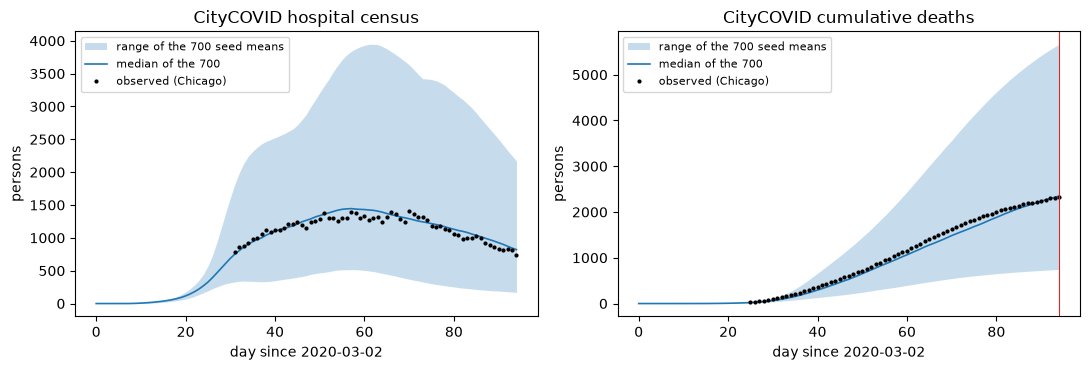

In [4]:
days = np.arange(Hosp.shape[1])
fig, axs = plt.subplots(1, 2, figsize=(11, 3.8))
for ax, Y, k, title in [(axs[0], Hosp, 2, 'hospital census'), (axs[1], Deaths, 1, 'cumulative deaths')]:
    ax.fill_between(days, Y.min(axis=0), Y.max(axis=0), color='tab:blue', alpha=0.25, lw=0, label='range of the 700 seed means')
    ax.plot(days, np.median(Y, axis=0), color='tab:blue', lw=1.2, label='median of the 700')
    ax.plot(Obs[:, 0], Obs[:, k], 'k.', ms=4, label='observed (Chicago)')
    ax.set_xlabel('day since 2020-03-02')
    ax.set_ylabel('persons')
    ax.set_title(f'CityCOVID {title}')
    ax.legend(loc='upper left', fontsize=8)
axs[1].axvline(days[-1], color='tab:red', lw=0.8)
fig.tight_layout()
plt.close(fig)
fig

The figure corresponds to the paper's Fig. 1 (p. 4): the range of the 700 seed-averaged trajectories and the
observed data (black). The red line marks 2020-06-04, the day of the quantity of interest.

In [5]:
f = Deaths[:, -1]                                   # QoI: cumulative deaths on 2020-06-04 (day 94)
print(f'f = cumulative deaths on 2020-06-04: min {f.min():.2f}, median {np.median(f):.2f}, max {f.max():.2f}, sd {f.std(ddof=1):.1f}')
print(f'observed on 2020-06-04: {Obs[Obs[:, 0] == 94, 1][0]:.0f}')

f = cumulative deaths on 2020-06-04: min 745.54, median 2348.05, max 5665.00, sd 1033.2
observed on 2020-06-04: 2331


### Input space and the seeding-time bounds

The seeding-time bounds used here are those of the **stored design, [31, 133]**, not Table 2's [31, 59]: all
700 rows can then be used, and the design is close to uniform over that interval (7.14 rows per unit in
[31, 59) and 6.76 in [59, 133], printed below). The other three inputs use the Table 2 bounds. Each input is
scaled through its uniform box to $[-1, 1]$ (`ac.Uniform`). The 200 rows inside Table 2's range are analysed
with the Table 2 bounds as a check further down.

In [6]:
LO = np.array([0.046, 31.0, 0.939, 0.407])          # theta2 bounds of the stored design: [31, 133]
HI = np.array([0.069, 133.0, 0.981, 0.492])
space = ac.Uniform(LO, HI, names=LABELS)
print('inputs inside the box:', bool(np.all((X >= LO) & (X <= HI))))
print('theta2 counts per unit length: [31, 59)', round(np.sum(t2 < 59) / 28, 2), ' [59, 133]', round(np.sum(t2 >= 59) / 74, 2))

inputs inside the box: True
theta2 counts per unit length: [31, 59) 7.14  [59, 133] 6.76


## Estimate the subspace

**Estimator.** CityCOVID computes no gradients, and finite differences would need new runs of a cluster code
that is not public, so the subspace is estimated from the $M = 700$ values. QPHD fits a full quadratic
(15 coefficients for $m = 4$, printed below) to 700 points, so the fit is well determined; it gives all four eigenvalues and
thus an eigenvalue gap, which OLS (one direction) cannot. QPHD's derivation assumes Gaussian inputs; on a
uniform space the package warns (silenced in the first cell) and uses the covariance $\tfrac13\mathbf{I}$ of
the uniform reference density, so the matrix is the average of $\nabla q\,\nabla q^\top$ over the box. OLS is
computed as a check of the first direction. The bootstrap has 200 replicates drawn from `SEED`.
**Signs** (no published active subspace): each eigenvector is oriented so that its active variable has a
positive covariance with $f$ (`ac.orient(by='covariance')`).

Because the outputs are means over 50 seeds, $f$ carries seed noise of unknown size; the stored files have no
per-seed values.

In [7]:
# n = 2 here only so that the bootstrap keeps two eigenvectors; the dimension is chosen below.
sub = ac.active_subspace(space=space, X=X, f=f, estimator='qphd', n=2, nboot=200, bootstrap_vectors=2, rng=SEED)
sub = ac.orient(sub, by='covariance', X=X, f=f, columns=2)
ols = ac.active_subspace(space=space, X=X, f=f, estimator='ols', n=1)
ols = ac.orient(ols, by='covariance', X=X, f=f)
print(f'M = {M} samples, m = {m} inputs, {(m + 1) * (m + 2) // 2} coefficients in the quadratic fit')
lam = sub.eigenvalues
ci = ac.bootstrap_interval(sub.bootstrap_eigenvalues)
print('QPHD eigenvalues (normalized inputs, deaths^2) with 95% bootstrap intervals:')
for k in range(m):
    print(f'  lambda_{k + 1} = {lam[k]:.4g}   [{ci[0, k]:.4g}, {ci[1, k]:.4g}]')
print('ratios lambda_k / lambda_k+1:', np.round(lam[:-1] / lam[1:], 2))
print('share of the trace left out by n = 1:', round(lam[1:].sum() / lam.sum(), 4), ' by n = 2:', round(lam[2:].sum() / lam.sum(), 4))
dist = sub.bootstrap_distances.mean(axis=0)
print('bootstrap mean subspace distance for n = 1, 2, 3:', np.round(dist, 3))
print('w1 (QPHD):', np.round(sub.W[:, 0], 3))
print('w2 (QPHD):', np.round(sub.W[:, 1], 3))
print('w1 (OLS): ', np.round(ols.W[:, 0], 3), '  |w1_QPHD . w1_OLS| =', round(abs(sub.W[:, 0] @ ols.W[:, 0]), 5))

M = 700 samples, m = 4 inputs, 15 coefficients in the quadratic fit
QPHD eigenvalues (normalized inputs, deaths^2) with 95% bootstrap intervals:
  lambda_1 = 3.272e+06   [3.221e+06, 3.333e+06]
  lambda_2 = 7.447e+04   [6.263e+04, 8.731e+04]
  lambda_3 = 1.217e+04   [8189, 1.852e+04]
  lambda_4 = 1527   [695.6, 2915]
ratios lambda_k / lambda_k+1: [43.94  6.12  7.97]
share of the trace left out by n = 1: 0.0262  by n = 2: 0.0041
bootstrap mean subspace distance for n = 1, 2, 3: [0.006 0.044 0.066]
w1 (QPHD): [ 0.834 -0.263 -0.441  0.203]
w2 (QPHD): [-0.349 -0.932 -0.095  0.021]
w1 (OLS):  [ 0.835 -0.263 -0.441  0.2  ]   |w1_QPHD . w1_OLS| = 0.99999


The first eigenvalue is 3.272e+06 (95 % bootstrap interval 3.221e+06 to 3.333e+06) and the second 7.447e+04
(6.263e+04 to 8.731e+04): $\lambda_1/\lambda_2$ = 43.94, while the next two ratios (6.12 and 7.97) are
comparable to each other. The first direction leaves 0.0262 of the trace out, the first two 0.0041. The
bootstrap mean subspace distance is 0.006 for $n = 1$ and 0.044 for $n = 2$, and the OLS direction agrees with
the QPHD $w_1$ to $|w_1^{\rm QPHD}\cdot w_1^{\rm OLS}|$ = 0.99999.

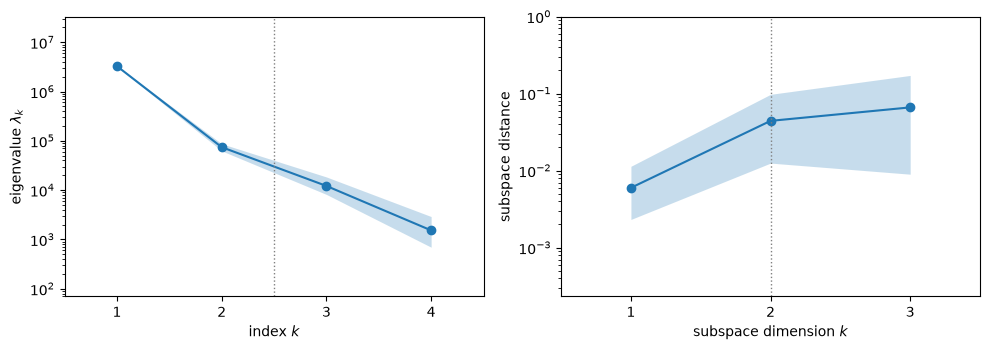

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(10, 3.6))
ac.plotting.plot_eigenvalues(sub, ax=axs[0])
ac.plotting.plot_subspace_errors(sub, ax=axs[1])
fig.tight_layout()
plt.close(fig)
fig

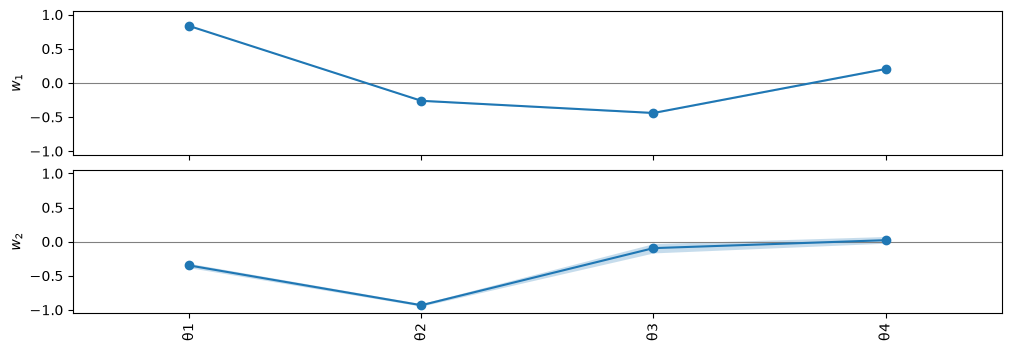

In [9]:
fig, axs = ac.plotting.plot_eigenvectors(sub, indices=[0, 1], labels=LABELS, interval='percentile', figsize=(10, 3.4))
plt.close(fig)
fig

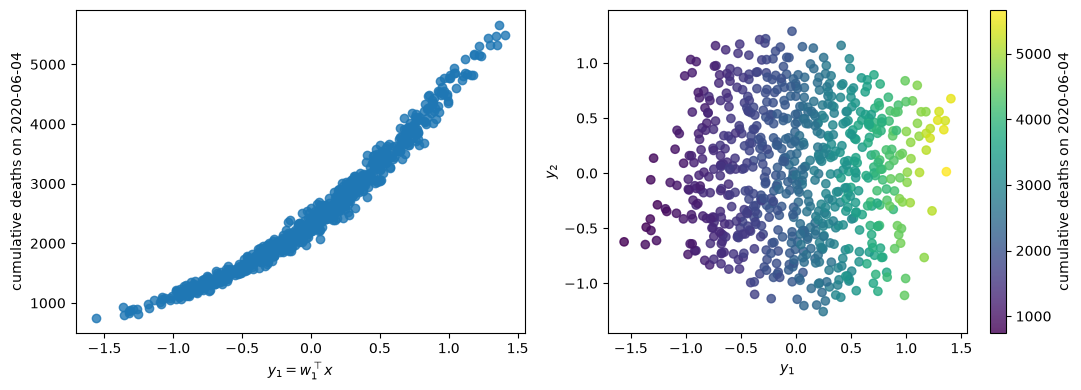

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(11, 4))
ac.plotting.plot_sufficient_summary(sub, X=X, f=f, dims=1, qoi_label='cumulative deaths on 2020-06-04', ax=axs[0])
ac.plotting.plot_sufficient_summary(sub, X=X, f=f, dims=2, qoi_label='cumulative deaths on 2020-06-04', ax=axs[1])
fig.tight_layout()
plt.close(fig)
fig

$w_1$ = (0.834, −0.263, −0.441, 0.203): deaths rise with the exposure rate $\theta_1$ and the probability of
protective behaviours $\theta_4$ and fall with the stay-at-home probability $\theta_3$ and with a later seeding
time $\theta_2$, in normalized coordinates. (A positive weight for protective behaviours is what the data
show; the notebook does not interpret it.) The second direction, $w_2$ = (−0.349, −0.932, −0.095, 0.021), is
mostly the seeding time. The one-dimensional sufficient summary plot is a tight, slightly convex curve; the
colouring of the two-dimensional plot changes mainly along the first axis.

### Dimension

The notebook uses **$n = 1$**. The gap after the first eigenvalue ($\lambda_1/\lambda_2$ = 43.94) is the only
large one, the bootstrap distance of the one-dimensional subspace is small (0.006), and a quadratic in the one
active variable has leave-one-out $R^2$ 0.9858 (below). Adding the second direction raises it to 0.9909, and a
cubic in all four inputs reaches 0.9932: the directions beyond the first carry a real but small part of the variation
(0.0262 of the trace), most of it in the second direction, which is mostly the seeding time, examined next.

In [11]:
print('LOO R^2 of polynomial surrogates on the active variables (QPHD subspace from all rows):')
for n in (1, 2):
    sn = ac.with_dimension(sub, n)
    for deg in (2, 3):
        g = ac.fit_surrogate(X=X, f=f, subspace=sn, kind='poly', degree=deg)
        print(f'  n = {n}, degree {deg}: {g.loo_r_squared:.4f}   LOO RMS residual {np.sqrt(np.mean(g.loo_residuals ** 2)):.1f} deaths')
g4 = ac.fit_surrogate(X=X, f=f, space=space, subspace=None, kind='poly', degree=3)
print(f'  all 4 inputs, degree 3: {g4.loo_r_squared:.4f}')

LOO R^2 of polynomial surrogates on the active variables (QPHD subspace from all rows):
  n = 1, degree 2: 0.9858   LOO RMS residual 123.2 deaths
  n = 1, degree 3: 0.9857   LOO RMS residual 123.4 deaths
  n = 2, degree 2: 0.9909   LOO RMS residual 98.6 deaths
  n = 2, degree 3: 0.9916   LOO RMS residual 94.5 deaths
  all 4 inputs, degree 3: 0.9932


## Surrogate on the active variable

The leave-one-out $R^2$ values printed in the dimension cell are those of polynomial surrogates
(`ac.fit_surrogate(kind='poly')`) on the active variables of the QPHD subspace estimated from all 700 rows (the
direction is not refitted in each fold). A quadratic in $w_1^\top x$ has LOO $R^2$ 0.9858 and LOO RMS residual
123.2 deaths, against a standard deviation of $f$ over the design of 1033.2 deaths: one linear combination of
the four inputs predicts the 2020-06-04 death count closely.

### The seeding time acts as a step function

The paper notes that $\theta_2$ "is aligned on 24 hour boundaries" (p. 8). The data agree with a seeding time
in hours rounded to the nearest whole day: replacing $\theta_2$ by the factor $\lfloor(\theta_2 + 12)/24\rfloor$
(the nearest multiple of 24) lowers the leave-one-out RMS residual from 92.2 deaths (a quadratic in all four
inputs) to 51.8, while other offsets (0, 6, 18 hours) give 113.4–129.8. The unit is an inference: the paper
gives none, and a seeding time in days would not fit the stored series, in which hospitalizations begin
within the first two weeks of March for every row. The residual plot below (deaths minus a quadratic in the
other three inputs) shows the jumps at $24k + 12$.

So $f$ is piecewise constant in $\theta_2$, with six levels in the stored range (1 to 6 days), and its
derivative in $\theta_2$ is zero between the jumps. The $\theta_2$ weight of QPHD is the slope of the fitted
quadratic across the jumps, the trend of $f$ over the whole range, not a derivative of $f$.

In [12]:
Z = 2 * (X - LO) / (HI - LO) - 1                     # normalized inputs, as inside ac.Uniform


def loo_rms(A, y):
    """Leave-one-out root-mean-square residual of the least-squares fit y ~ A (hat-matrix formula)."""
    coef = np.linalg.lstsq(A, y, rcond=None)[0]
    h = np.einsum('ij,ji->i', A, np.linalg.pinv(A))
    return np.sqrt(np.mean(((y - A @ coef) / (1 - h)) ** 2))


def quad(Zc):
    cols = [np.ones(len(Zc))] + [Zc[:, i] for i in range(Zc.shape[1])]
    cols += [Zc[:, i] * Zc[:, j] for i in range(Zc.shape[1]) for j in range(i, Zc.shape[1])]
    return np.column_stack(cols)


smooth = loo_rms(quad(Z), f)
print(f'quadratic in all four inputs: LOO RMS residual {smooth:.1f} deaths')
others = quad(Z[:, [0, 2, 3]])[:, 1:]
for off in (0, 6, 12, 18):
    day = np.floor((t2 + off) / 24).astype(int)
    D1 = (day[:, None] == np.unique(day)[None, :]).astype(float)
    A = np.column_stack([D1, others, D1[:, 1:] * Z[:, [0]]])
    print(f'theta2 replaced by floor((theta2 + {off:2d}) / 24) as a factor: LOO RMS {loo_rms(A, f):.1f} deaths')
day = np.floor((t2 + 12) / 24).astype(int)
first = np.argmax(Hosp > 1, axis=1)
print('first day with census > 1, over the 700 rows: days', first.min(), 'to', first.max(), '(day 0 = 2020-03-02)')
print('levels of round(theta2 / 24) and row counts:', dict(zip(*[a.tolist() for a in np.unique(day, return_counts=True)])))

quadratic in all four inputs: LOO RMS residual 92.2 deaths
theta2 replaced by floor((theta2 +  0) / 24) as a factor: LOO RMS 129.8 deaths
theta2 replaced by floor((theta2 +  6) / 24) as a factor: LOO RMS 113.6 deaths
theta2 replaced by floor((theta2 + 12) / 24) as a factor: LOO RMS 51.8 deaths
theta2 replaced by floor((theta2 + 18) / 24) as a factor: LOO RMS 113.4 deaths
first day with census > 1, over the 700 rows: days 7 to 11 (day 0 = 2020-03-02)
levels of round(theta2 / 24) and row counts: {1: 36, 2: 170, 3: 164, 4: 163, 5: 162, 6: 5}


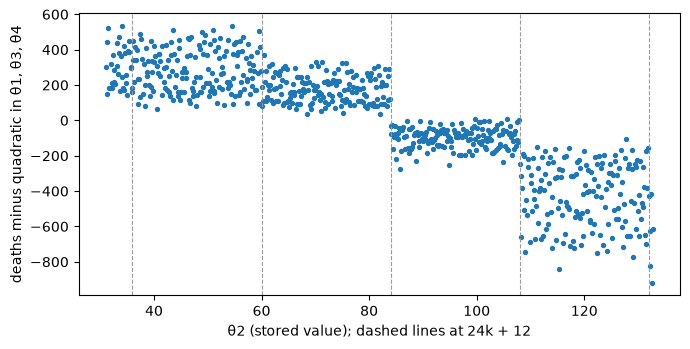

In [13]:
res = f - quad(np.delete(Z, 1, axis=1)) @ np.linalg.lstsq(quad(np.delete(Z, 1, axis=1)), f, rcond=None)[0]
fig, ax = plt.subplots(figsize=(7, 3.6))
ax.scatter(t2, res, s=8, c='tab:blue')
for k in range(1, 6):
    ax.axvline(24 * k + 12, color='0.6', lw=0.8, ls='--')
ax.set_xlabel('θ2 (stored value); dashed lines at 24k + 12')
ax.set_ylabel('deaths minus quadratic in θ1, θ3, θ4')
fig.tight_layout()
plt.close(fig)
fig

### Check: the 200 rows inside the Table 2 prior

With the Table 2 bounds and only the rows with $\theta_2 \le 59$ ($M = 200$, still well above the 15
coefficients of the quadratic), $\lambda_1/\lambda_2$ = 206.01 and $w_1$ = (0.876, −0.006, −0.438, 0.201):
the exposure-rate, stay-at-home and protective-behaviour weights are close to those of the full design, and
the seeding time drops out. Inside [31, 59] the nearest whole day takes only the values 1 and 2 (one jump at
36), and the data show no measurable trend there.

In [14]:
inside = t2 <= 59
space2 = ac.Uniform(LO_T2, HI_T2, names=LABELS)
sub2 = ac.active_subspace(space=space2, X=X[inside], f=f[inside], estimator='qphd', n=1, nboot=200, rng=SEED)
sub2 = ac.orient(sub2, by='covariance', X=X[inside], f=f[inside])
lam2 = sub2.eigenvalues
print(f'{inside.sum()} rows with theta2 in Table 2 range [31, 59], space = Table 2 priors')
print('levels of round(theta2 / 24) among them:', dict(zip(*[a.tolist() for a in np.unique(day[inside], return_counts=True)])))
print('QPHD eigenvalues:', np.array2string(lam2, precision=4), ' ratios:', np.round(lam2[:-1] / lam2[1:], 2))
print('w1:', np.round(sub2.W[:, 0], 3), ' bootstrap mean distance n=1:', round(sub2.bootstrap_distances.mean(axis=0)[0], 3))
g2 = ac.fit_surrogate(X=X[inside], f=f[inside], subspace=sub2, kind='poly', degree=2)
print(f'LOO R^2, quadratic in w1^T x: {g2.loo_r_squared:.4f}')

200 rows with theta2 in Table 2 range [31, 59], space = Table 2 priors
levels of round(theta2 / 24) among them: {1: 36, 2: 164}
QPHD eigenvalues: [3.7265e+06 1.8089e+04 2.2660e+03 6.3667e+02]  ratios: [206.01   7.98   3.56]
w1: [ 0.876 -0.006 -0.438  0.201]  bootstrap mean distance n=1: 0.005
LOO R^2, quadratic in w1^T x: 0.9965


## Comparison with the paper

The paper has no active subspace. Its sensitivity results (Table 3, p. 20) are random-forest importances and
Sobol' indices of the surrogate of the whole PCA-compressed series (the table does not say which output or
coefficient they refer to); the notebook's quantity is one scalar, so the numbers are not the same quantity.

| quantity | paper (page) | notebook |
|---|---|---|
| design | 700 Halton points, 50 seeds each (p. 4) | 700 rows; every output a multiple of 1/50 |
| $\theta_2$ range | prior U(31, 59) (Table 2, p. 19) | stored 31.07–132.71; 500 rows above 59 |
| $\theta_1, \theta_3, \theta_4$ ranges | U(0.046, 0.069), U(0.939, 0.981), U(0.407, 0.492) (Table 2) | stored ranges inside these bounds |
| total Sobol' index of the surrogate, $\theta_1$ / $\theta_2$ / $\theta_3$ / $\theta_4$ | 0.56 / 0.33 / 0.09 / 0.01 (Table 3, p. 20) | not computed; squared $w_1$ components for 2020-06-04 deaths 0.695 / 0.069 / 0.195 / 0.041 |
| least influential input | $\theta_4$ (Table 3; p. 8) | $\theta_4$ (smallest $w_1$ weight, 0.203) |
| $\theta_1$–$\theta_3$ posterior correlation | strongly positive (Fig. 4, p. 8) | level sets of $f$ have slope $d\theta_3/d\theta_1$ = 1.891 (normalized), so equal deaths need $\theta_1$ and $\theta_3$ to rise together |
| PCA of the series | 4 components capture over 95 % of the variance (Fig. 3, p. 7) | centred, unscaled concatenated series: 1 component 0.9601, 4 components 0.9997 (the paper's scaling is not stated) |
| active subspace, eigenvalue gap | not reported | $\lambda_1/\lambda_2$ = 43.94, $n = 1$ |
| leave-one-out $R^2$ | not reported (random forest: median absolute relative error < 5 % in 5-fold CV, p. 7) | 0.9858 (quadratic in $w_1^\top x$) |

The ranking differs: the paper ranks the seeding time second (total Sobol' 0.33), the notebook ranks it third
for this scalar (0.069 of $\|w_1\|^2$). A plausible reason is that the seeding time shifts the timing of the
epidemic, which the whole series registers more than the end-of-window death count; the notebook does not test
this. The positive $\theta_1$–$\theta_3$ posterior correlation is what the direction predicts: deaths stay
fixed along a line on which both inputs increase.

In [15]:
w = sub.W[:, 0]
print('w1 components squared:', np.round(w ** 2, 3))
print('activity scores (n = 1), normalized to sum 1:', np.round(ac.activity_scores(sub, 1) / ac.activity_scores(sub, 1).sum(), 3))
print(f'level-set slope d theta3 / d theta1 along f = const (normalized inputs): {-w[0] / w[2]:.3f}')
Y = np.hstack([Hosp, Deaths])
s = np.linalg.svd(Y - Y.mean(axis=0), compute_uv=False)
share = np.cumsum(s ** 2) / np.sum(s ** 2)
print('PCA of the concatenated series (centred, unscaled): variance share of 1-4 components', np.round(share[:4], 4))
print(f'notebook run time {time.perf_counter() - t_start:.1f} s')

w1 components squared: [0.695 0.069 0.195 0.041]
activity scores (n = 1), normalized to sum 1: [0.695 0.069 0.195 0.041]
level-set slope d theta3 / d theta1 along f = const (normalized inputs): 1.891
PCA of the concatenated series (centred, unscaled): variance share of 1-4 components [0.9601 0.9957 0.9987 0.9997]
notebook run time 2.1 s


## References

- C. Robertson, C. Safta, N. Collier, J. Ozik, J. Ray. Bayesian calibration of stochastic agent based model via
  random forest. *Statistics in Medicine* 44(6):e70029, 2025. [doi:10.1002/sim.70029](https://doi.org/10.1002/sim.70029).
  Data and code: https://github.com/sandialabs/Bayesian-calibration-of-stochastic-agent-based-model-via-random-forest
  (MIT licence).
- J. Ozik, J. M. Wozniak, N. Collier, C. M. Macal, M. Binois. A population data-driven workflow for COVID-19
  modeling and learning. *The International Journal of High Performance Computing Applications*
  35(5):483–499, 2021 (as cited by the paper, ref. 22).
- T.-T. Wong, W.-S. Luk, P.-A. Heng. Sampling with Hammersley and Halton points. *Journal of Graphics Tools*
  2(2):9–24, 1997 (as cited by the paper, ref. 45).
- K.-C. Li. On principal Hessian directions for data visualization and dimension reduction: another
  application of Stein's lemma. *Journal of the American Statistical Association* 87(420):1025–1039, 1992.
- P. G. Constantine. *Active Subspaces: Emerging Ideas for Dimension Reduction in Parameter Studies*. SIAM,
  2015. [doi:10.1137/1.9781611973860](https://doi.org/10.1137/1.9781611973860).

## Acknowledgments

The paper (p. 1 and p. 15) acknowledges support from the US Department of Energy Office of Science, Advanced
Scientific Computing Research, through the Bio-preparedness Research Virtual Environment (BRaVE) initiative;
the National Science Foundation under Grant 2200234; the US Department of Energy, Office of Science, under
contract DE-AC02-06CH11357; and computing resources of the Laboratory Computing Resource Center at Argonne
National Laboratory. The article was authored by an employee of NTESS under contract DE-NA0003525 with the
US Department of Energy (p. 15).